# Лабораторная работа № 3. Задание № 2.
> Григорьев Никита M3338, Паховский Иван M3339

## Условие варианта

Распределение Лапласса с неизвестным параметром сдвига $\mu$ и единичным масштабирующим параметром; $\mu$; $\mu = 2$;

## Выкладки

$X_1, \dots, X_n \sim \text{Laplace}(\mu, 1)$, плотность $f(x) = \frac{1}{2} e^{-|x - \mu|}$.

$\mathbb{E}X_i = \mathbb{Med}X_i = \mu$

Хотим придумать центральную статистику, чтобы с помощью уже известного нам выражения $\mathbb{P}(q_{\frac{\alpha}{2}} \le G(X, \theta) \le q_{1-\frac{\alpha}{2}}) = 1-\alpha$ построить доверительный интервал для $\mu$.

### Способ 1. Через выборочное среднее.
$$\sqrt{n}\frac{(\overline{X} - \mu)}{\sigma} \overset d\longrightarrow \mathcal{N}(0,1) \quad \text{по ЦПТ.}$$

То есть $\sqrt{n}\frac{(\overline{X} - \mu)}{\sigma}$ является центральной статистикой.

Тогда доверительный интервал выглядит следующим образом:

$$\mathbb{P}(-\frac{\sqrt{2}}{\sqrt{n}}q_{1-\frac{\alpha}{2}} + \overline{X} \le\mu\le -\frac{\sqrt{2}}{\sqrt{n}}q_{\frac{\alpha}{2}} + \overline{X})$$

 ### Способ 2. Через выборочную медиану.

Воспользуемся **Теоремой об асимптотике средних членов вариационного ряда**:

$$\sqrt{n}\frac{X_{(\lceil np\rceil)}-q_p}{\sqrt{p(1-p)}}f(q_q) d\longrightarrow \mathcal{N}(0,1)$$

$$\sqrt{n}\frac{\hat{q_{\frac{1}{2}}}-\mu}{\sqrt{\frac{1}{2}(1-\frac{1}{2})}}f(\mu) d\longrightarrow \mathcal{N}(0,1)$$

В случае распределения Лапласа $\frac{f(\mu)}{\sqrt{\frac{1}{2}(1-\frac{1}{2})}} = 1$, тогда итоговый интервал похож на тот, который мы находили с помощью выборочного среднего:

$$\mathbb{P}(-\frac{1}{\sqrt{n}}q_{1-\frac{\alpha}{2}} + \hat{q_{\frac{1}{2}}} \le\mu\le -\frac{1}{\sqrt{n}}q_{\frac{\alpha}{2}} + \hat{q_{\frac{1}{2}}})$$


In [1]:
import numpy as np
import scipy.stats

MU = 2
SCALE = 1

ALPHA = 0.1

SAMPLE_SIZES = [10, 100, 1000, 10000, 100000, 500000]
NUM_SAPLES = 5000

In [2]:
def calc_confidence_interval_mean(X, alpha):
    return (- scipy.stats.norm.ppf(1 - alpha / 2) * np.sqrt(2) / np.sqrt(len(X)) + np.mean(X),
            - scipy.stats.norm.ppf(alpha / 2) * np.sqrt(2) / np.sqrt(len(X)) + np.mean(X))


def calc_confidence_interval_median(X, alpha):
    return (- scipy.stats.norm.ppf(1 - alpha / 2) / np.sqrt(len(X)) + np.median(X),
            - scipy.stats.norm.ppf(alpha / 2) / np.sqrt(len(X)) + np.median(X))

In [3]:
def run(num_samples, one_sample_size, alpha):
    global MU, SCALE

    intervals_mean = []
    good_intervals_count_mean = 0
    bad = 0

    intervals_median = []
    good_intervals_count_median = 0

    for _ in range(num_samples):
        X = np.random.laplace(MU, SCALE, one_sample_size)

        mu_l_mean, mu_r_mean = calc_confidence_interval_mean(X, alpha)
        mu_l_median, mu_r_median = calc_confidence_interval_median(X, alpha)

        if MU >= mu_l_mean and MU <= mu_r_mean:
            good_intervals_count_mean += 1

        if MU >= mu_l_median and MU <= mu_r_median:
            good_intervals_count_median += 1

        intervals_mean.append((mu_l_mean, mu_r_mean))
        intervals_median.append((mu_l_median, mu_r_median))

    return (intervals_mean, good_intervals_count_mean, intervals_median, good_intervals_count_median)

N = 10
Good intervals for mean estimate : 4508
Good intervals for mean estimate: 0.9016
Good intervals for median estimate : 4193
Good intervals for median estimate: 0.8386
Mean interval_mean: (1.2611024045500836, 2.7323042137103046)
Mean interval_mean len: 1.471201809160221
Mean interval_median: (1.4793743542394808, 2.5196711299905896)
Mean interval_median len: 1.0402967757511088

N = 100
Good intervals for mean estimate : 4508
Good intervals for mean estimate: 0.9016
Good intervals for median estimate : 4410
Good intervals for median estimate: 0.882
Mean interval_mean: (1.7672452816326276, 2.2324801431032864)
Mean interval_mean len: 0.46523486147065873
Mean interval_median: (1.8363689296444206, 2.1653396550347175)
Mean interval_median len: 0.3289707253902969

N = 1000
Good intervals for mean estimate : 4474
Good intervals for mean estimate: 0.8948
Good intervals for median estimate : 4446
Good intervals for median estimate: 0.8892
Mean interval_mean: (1.9271808694082446, 2.0743010503

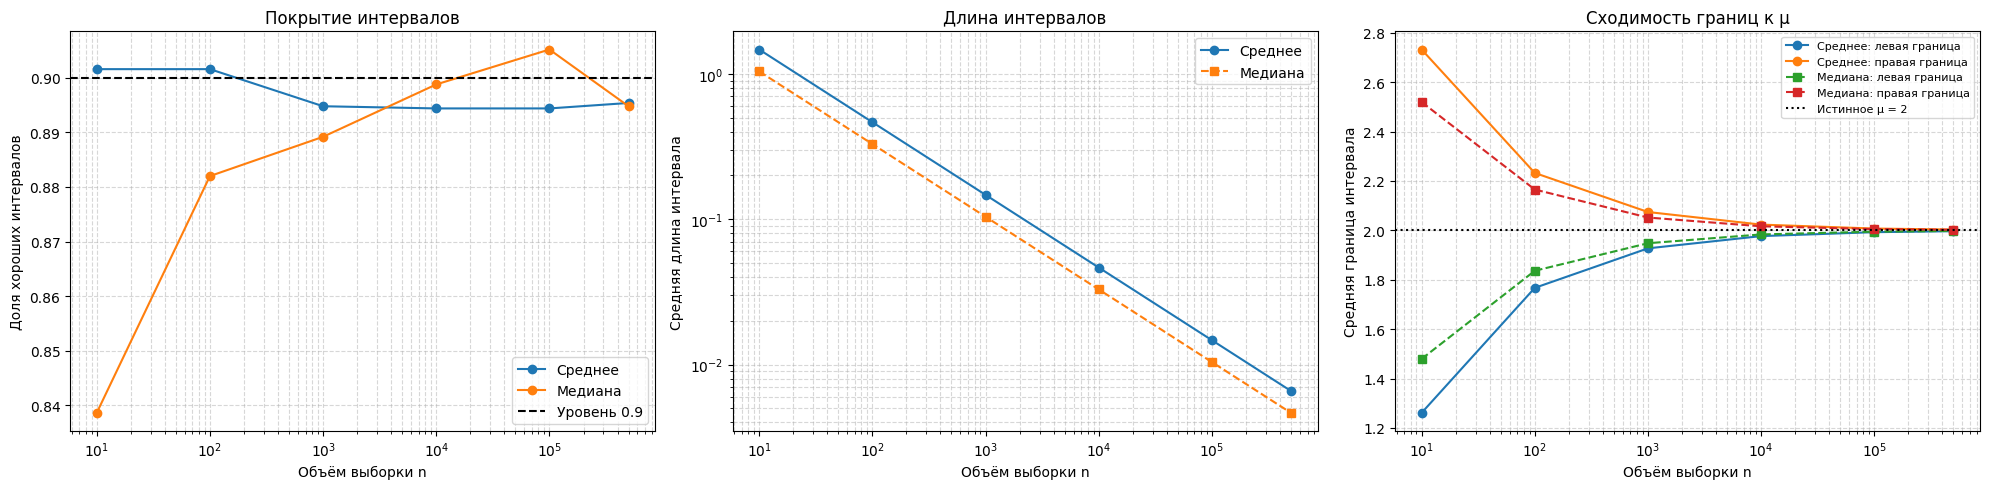

In [4]:
import matplotlib.pyplot as plt

coverage_mean = []
coverage_median = []
length_mean = []
length_median = []
lower_mean = []
upper_mean = []
lower_median = []
upper_median = []

for i in SAMPLE_SIZES:
    intervals_mean, good_intervals_mean, intervals_median, good_intervals_median = run(NUM_SAPLES, i, ALPHA)

    print(f'N = {i}')
    print(f'Good intervals for mean estimate : {good_intervals_mean}')
    print(f'Good intervals for mean estimate: {good_intervals_mean / NUM_SAPLES}')

    print(f'Good intervals for median estimate : {good_intervals_median}')
    print(f'Good intervals for median estimate: {good_intervals_median / NUM_SAPLES}')

    firsts_mean, seconds_mean = zip(*intervals_mean)
    result = (sum(firsts_mean) / len(intervals_mean), sum(seconds_mean) / len(intervals_mean))

    print(f'Mean interval_mean: ({result[0]}, {result[1]})')
    print(f'Mean interval_mean len: {result[1] - result[0]}')

    firsts_median, seconds_median = zip(*intervals_median)
    result = (sum(firsts_median) / len(intervals_median), sum(seconds_median) / len(intervals_median))

    print(f'Mean interval_median: ({result[0]}, {result[1]})')
    print(f'Mean interval_median len: {result[1] - result[0]}')

    print()

    coverage_mean.append(good_intervals_mean / NUM_SAPLES)
    coverage_median.append(good_intervals_median / NUM_SAPLES)
    length_mean.append(np.mean(np.asarray(seconds_mean) - np.asarray(firsts_mean)))
    length_median.append(np.mean(np.asarray(seconds_median) - np.asarray(firsts_median)))
    lower_mean.append(np.mean(firsts_mean))
    upper_mean.append(np.mean(seconds_mean))
    lower_median.append(np.mean(firsts_median))
    upper_median.append(np.mean(seconds_median))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].plot(SAMPLE_SIZES, coverage_mean, marker='o', label='Среднее')
axes[0].plot(SAMPLE_SIZES, coverage_median, marker='o', label='Медиана')
axes[0].axhline(1 - ALPHA, color='black', linestyle='--', label=f'Уровень {1 - ALPHA}')
axes[0].set_xscale('log')
axes[0].set_xlabel('Объём выборки n')
axes[0].set_ylabel('Доля хороших интервалов')
axes[0].set_title('Покрытие интервалов')
axes[0].grid(True, which='both', linestyle='--', alpha=0.5)
axes[0].legend()

axes[1].plot(SAMPLE_SIZES, length_mean, marker='o', label='Среднее')
axes[1].plot(SAMPLE_SIZES, length_median, marker='s', linestyle='--', label='Медиана')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Объём выборки n')
axes[1].set_ylabel('Средняя длина интервала')
axes[1].set_title('Длина интервалов')
axes[1].grid(True, which='both', linestyle='--', alpha=0.5)
axes[1].legend()

axes[2].plot(SAMPLE_SIZES, lower_mean, marker='o', label='Среднее: левая граница')
axes[2].plot(SAMPLE_SIZES, upper_mean, marker='o', label='Среднее: правая граница')
axes[2].plot(SAMPLE_SIZES, lower_median, marker='s', linestyle='--', label='Медиана: левая граница')
axes[2].plot(SAMPLE_SIZES, upper_median, marker='s', linestyle='--', label='Медиана: правая граница')
axes[2].axhline(MU, color='black', linestyle=':', label=f'Истинное μ = {MU}')
axes[2].set_xscale('log')
axes[2].set_xlabel('Объём выборки n')
axes[2].set_ylabel('Средняя граница интервала')
axes[2].set_title('Сходимость границ к μ')
axes[2].grid(True, which='both', linestyle='--', alpha=0.5)
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()